# ARIMA vs FastARIMA y FBProphet vs FastProphet (datos sintéticos)

Comparación sencilla de los modelos originales contra sus reemplazos vectorizados:

| Original | Reemplazo |
|---|---|
| `ARIMA` (statsmodels SARIMAX) | `FastARIMA` (Hannan-Rissanen + Levenberg-Marquardt, todas las series a la vez) |
| `FBProphet` (Stan) | `FastProphet` (IRLS en forma cerrada, todas las series a la vez) |

Se generan 3 series con estructura conocida, se ajustan los 4 modelos, y se comparan **tiempos, error, cobertura del intervalo, parámetros ajustados y gráficas**.
`FBProphet` requiere el paquete opcional `prophet`; si no está instalado esas celdas se omiten y el resto funciona.

In [13]:
import sys, time, warnings, logging
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
for noisy in ("cmdstanpy", "prophet"):
    logging.getLogger(noisy).setLevel(logging.ERROR)
    logging.getLogger(noisy).disabled = True

# permite ejecutar el notebook desde examples/ sin instalar el paquete
repo_root = Path.cwd() if (Path.cwd() / "autots").exists() else Path.cwd().parent
sys.path.insert(0, str(repo_root))

from autots.models.statsmodels import ARIMA
from autots.models.fast_arima import FastARIMA
from autots.models.prophet import FBProphet
from autots.models.fast_prophet import FastProphet

try:
    from prophet import Prophet
    HAVE_PROPHET = True
except Exception:
    HAVE_PROPHET = False
print("prophet instalado:", HAVE_PROPHET)

Importing plotly failed. Interactive plots will not work.


prophet instalado: True


## 1. Datos sintéticos

Tres series diarias (3 años) con la verdad conocida, para poder juzgar los ajustes:

1. **`arima_like`**: un ARIMA(2,1,1) con coeficientes reales `phi=(0.6, -0.25)`, `theta=0.4`.
2. **`trend_weekly`**: tendencia lineal + estacionalidad semanal + ruido.
3. **`changepoint_yearly`**: pendiente que cambia de +0.05 a -0.10 por día en el día 700, + estacionalidad anual y semanal.

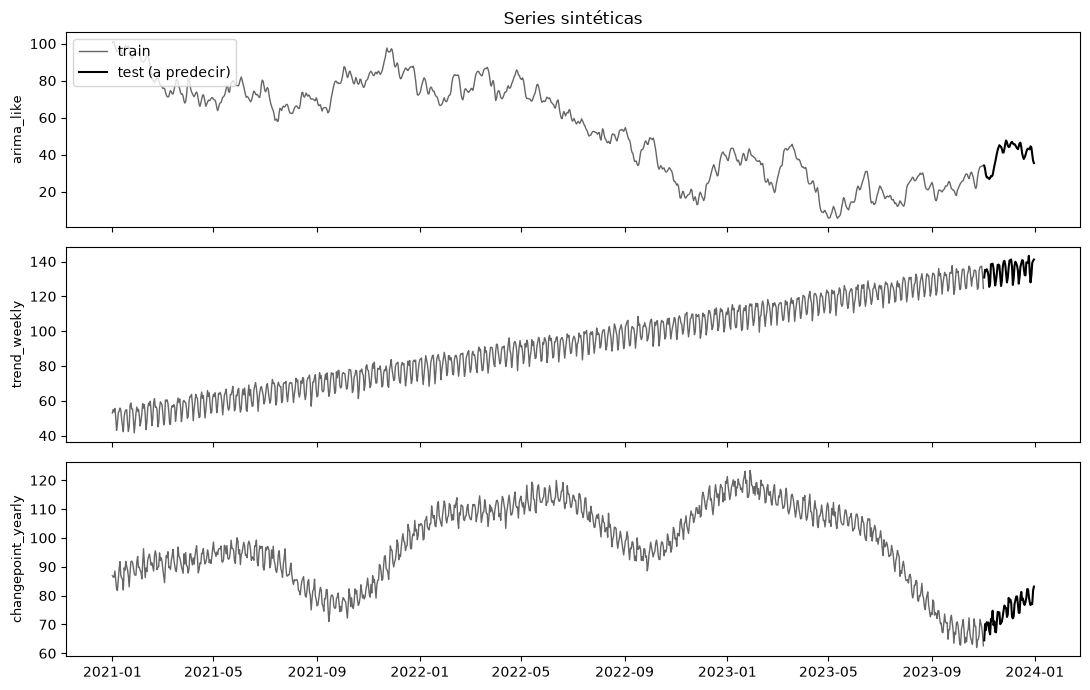

In [14]:
rng = np.random.default_rng(42)
N_ROWS, HORIZON = 1095, 60
index = pd.date_range("2021-01-01", periods=N_ROWS, freq="D")
t = np.arange(N_ROWS)

# 1) ARIMA(2,1,1) con coeficientes conocidos
TRUE_PHI, TRUE_THETA = np.array([0.6, -0.25]), np.array([0.4])
shocks = rng.normal(0, 1.0, N_ROWS + 50)
increments = np.zeros_like(shocks)
for i in range(2, len(shocks)):
    increments[i] = (TRUE_PHI[0] * increments[i - 1] + TRUE_PHI[1] * increments[i - 2]
                     + shocks[i] + TRUE_THETA[0] * shocks[i - 1])
arima_like = 100 + np.cumsum(increments[50:])

# 2) tendencia + estacionalidad semanal
trend_weekly = (50 + 0.08 * t + 6 * np.sin(2 * np.pi * t / 7)
                + 2 * np.cos(4 * np.pi * t / 7) + rng.normal(0, 1.5, N_ROWS))

# 3) cambio de pendiente + estacionalidad anual y semanal
CHANGEPOINT_DAY = 700
slope = np.where(t < CHANGEPOINT_DAY, 0.05, -0.10)
changepoint_yearly = (80 + np.cumsum(slope) + 12 * np.sin(2 * np.pi * t / 365.25)
                      + 5 * np.cos(4 * np.pi * t / 365.25) + 3 * np.sin(2 * np.pi * t / 7)
                      + rng.normal(0, 1.5, N_ROWS))

df = pd.DataFrame({"arima_like": arima_like, "trend_weekly": trend_weekly,
                   "changepoint_yearly": changepoint_yearly}, index=index)
train, test = df.iloc[:-HORIZON], df.iloc[-HORIZON:]

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, col in zip(axes, df.columns):
    ax.plot(train.index, train[col], color="0.4", lw=1, label="train")
    ax.plot(test.index, test[col], color="black", lw=1.5, label="test (a predecir)")
    ax.set_ylabel(col, fontsize=9)
axes[0].legend(loc="upper left"); axes[0].set_title("Series sintéticas")
plt.tight_layout(); plt.show()

## 2. Ajuste de los 4 modelos

Se miden tiempo (fit + predict), MAE sobre los últimos 60 días, y el intervalo del 90% (cobertura = fracción de puntos reales dentro del intervalo; ideal ≈ 0.90).

In [15]:
MODELS = {
    "ARIMA":       (ARIMA,       dict(p=2, d=1, q=1, n_jobs=1)),
    "FastARIMA":   (FastARIMA,   dict(p=2, d=1, q=1)),
    "FBProphet":   (FBProphet,   dict(n_jobs=1)),
    "FastProphet": (FastProphet, dict()),
}
if not HAVE_PROPHET:
    MODELS.pop("FBProphet")

fitted = {}
for name, (cls, kwargs) in MODELS.items():
    start = time.perf_counter()
    model = cls(**kwargs)
    model.fit(train)
    prediction = model.predict(HORIZON)
    fitted[name] = (model, prediction, time.perf_counter() - start)

rows = []
for name, (model, pred, seconds) in fitted.items():
    inside = (test.values >= pred.lower_forecast.values) & (test.values <= pred.upper_forecast.values)
    row = {"modelo": name, "segundos": round(seconds, 3),
           "MAE medio": (pred.forecast - test).abs().mean().mean().round(3),
           "cobertura 90%": inside.mean().round(2),
           "ancho medio intervalo": (pred.upper_forecast - pred.lower_forecast).mean().mean().round(2)}
    row.update({f"MAE {c}": round((pred.forecast[c] - test[c]).abs().mean(), 2) for c in df.columns})
    rows.append(row)
results = pd.DataFrame(rows).set_index("modelo")
results

,segundos,MAE medio,cobertura 90%,ancho medio intervalo,MAE arima_like,MAE trend_weekly,MAE changepoint_yearly
modelo,,,,,,,
ARIMA,0.162,7.053,0.77,23.87,7.78,5.11,8.27
FastARIMA,0.112,7.287,0.93,26.65,7.78,5.09,8.99
FBProphet,0.501,4.686,0.75,10.18,11.84,1.16,1.06
FastProphet,0.002,4.667,0.76,10.18,11.77,1.17,1.07


## 3. Parámetros ajustados

### ARIMA: coeficientes de `arima_like` vs la verdad

Los wrappers de AutoTS no guardan el ajuste de statsmodels, así que para mostrar sus coeficientes se ajusta el mismo `SARIMAX(order=(2,1,1))` directamente. `FastARIMA` expone sus coeficientes en `.phi`, `.theta` y `.sigma2`.

In [16]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sm_fit = SARIMAX(train["arima_like"], order=(2, 1, 1)).fit(disp=False)
fast_model = fitted["FastARIMA"][0]
col = list(train.columns).index("arima_like")

coef_table = pd.DataFrame(
    {
        "verdad":        [*TRUE_PHI, *TRUE_THETA, 1.0],
        "statsmodels":   [*sm_fit.arparams, *sm_fit.maparams, sm_fit.params["sigma2"]],
        "FastARIMA":     [*fast_model.phi[col], *fast_model.theta[col], fast_model.sigma2[col]],
    },
    index=["phi_1", "phi_2", "theta_1", "sigma2"],
).round(3)
coef_table

,verdad,statsmodels,FastARIMA
phi_1,0.60,0.646,0.647
phi_2,-0.25,-0.276,-0.276
theta_1,0.40,0.439,0.439
sigma2,1.00,0.977,0.977


In [17]:
# coeficientes de FastARIMA para las tres series (solo para ver su forma)
pd.DataFrame({"phi_1": fast_model.phi[:, 0], "phi_2": fast_model.phi[:, 1],
              "theta_1": fast_model.theta[:, 0], "sigma2": fast_model.sigma2},
             index=train.columns).round(3)

,phi_1,phi_2,theta_1,sigma2
arima_like,0.647,-0.276,0.439,0.977
trend_weekly,0.797,-0.628,-0.896,11.729
changepoint_yearly,0.292,-0.303,-0.518,7.072


### Prophet: tendencia de `changepoint_yearly`

Se comparan la pendiente base `k`, el offset `m` y los cambios de pendiente (`delta`) por changepoint, en las unidades escaladas internas de Prophet (tiempo en [0,1], `y` dividido por su máximo absoluto, igual en ambos modelos).
La gráfica convierte eso a **pendiente implícita por día** y la contrasta con la verdad (+0.05 → -0.10 en el día 700).

In [18]:
fast_prophet = fitted["FastProphet"][0]
col = list(train.columns).index("changepoint_yearly")
y_scale = fast_prophet._y_scale[col]
span_days = fast_prophet._span_days
origin = train.index[0]

fast_coef = fast_prophet._trend_coef[col]            # [m, k, deltas...]
fast_cp_time = fast_prophet._changepoints
fast_delta = fast_coef[2:]

param_rows = {"FastProphet": {"k (pendiente base)": fast_coef[1], "m (offset)": fast_coef[0],
                              "n_changepoints": len(fast_delta),
                              "|delta| medio": np.abs(fast_delta).mean(),
                              "changepoints con |delta|>0.01": int((np.abs(fast_delta) > 0.01).sum())}}
if HAVE_PROPHET:
    ref = Prophet(); ref.fit(pd.DataFrame({"ds": train.index, "y": train["changepoint_yearly"].values}))
    ref_delta = ref.params["delta"].mean(axis=0)
    ref_cp_time = ref.changepoints_t
    param_rows["Prophet"] = {"k (pendiente base)": ref.params["k"].mean(), "m (offset)": ref.params["m"].mean(),
                             "n_changepoints": len(ref_delta), "|delta| medio": np.abs(ref_delta).mean(),
                             "changepoints con |delta|>0.01": int((np.abs(ref_delta) > 0.01).sum())}
pd.DataFrame(param_rows).round(4)

,FastProphet,Prophet
k (pendiente base),0.4181,0.4153
m (offset),0.6501,0.6507
n_changepoints,25.0000,25.0000
|delta| medio,0.0518,0.0522
changepoints con |delta|>0.01,5.0000,6.0000


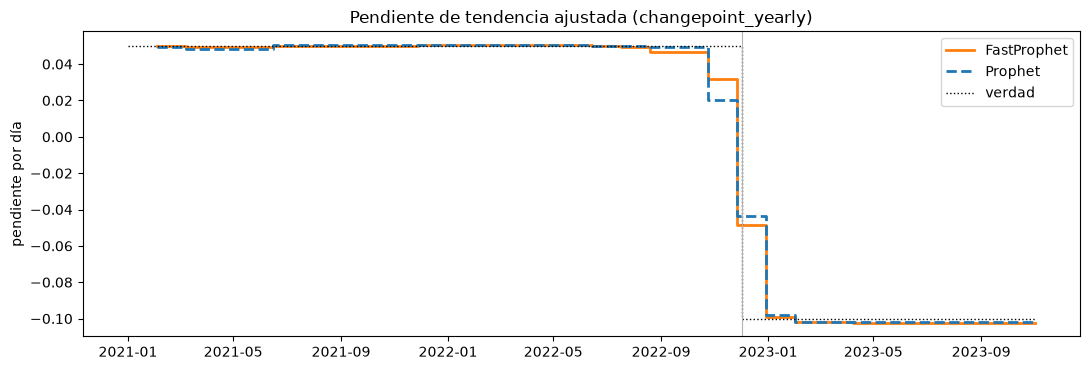

In [19]:
def slope_per_day(base_k, deltas):
    # pendiente por día en unidades originales (escalado tiempo -> días y y -> unidades de la serie)
    return (base_k + np.cumsum(deltas)) * y_scale / span_days

fig, ax = plt.subplots(figsize=(11, 3.8))
dates = lambda scaled: origin + pd.to_timedelta(np.asarray(scaled) * span_days, unit="D")
def extend_to_end(x, y):  # prolonga el último tramo hasta el final del entrenamiento
    return list(x) + [train.index[-1]], list(y) + [y[-1]]

fast_x, fast_y = extend_to_end(dates(fast_cp_time), slope_per_day(fast_coef[1], fast_delta))
ax.step(fast_x, fast_y, where="post",
        color="#ff7f0e", lw=2, label="FastProphet")
if HAVE_PROPHET:
    ref_x, ref_y = extend_to_end(dates(ref_cp_time), slope_per_day(ref.params["k"].mean(), ref_delta))
    ax.step(ref_x, ref_y, where="post",
            color="#1f77b4", lw=2, ls="--", label="Prophet")
truth_x = [train.index[0], index[CHANGEPOINT_DAY], index[CHANGEPOINT_DAY], train.index[-1]]
ax.plot(truth_x, [0.05, 0.05, -0.10, -0.10], color="black", lw=1, ls=":", label="verdad")
ax.axvline(index[CHANGEPOINT_DAY], color="0.7", lw=0.8)
ax.set_ylabel("pendiente por día"); ax.set_title("Pendiente de tendencia ajustada (changepoint_yearly)")
ax.legend(); plt.tight_layout(); plt.show()

## 4. Pronósticos

Izquierda: familia ARIMA. Derecha: familia Prophet. Línea punteada/azul = original, línea sólida/naranja = rápido; las bandas son el intervalo del 90%.

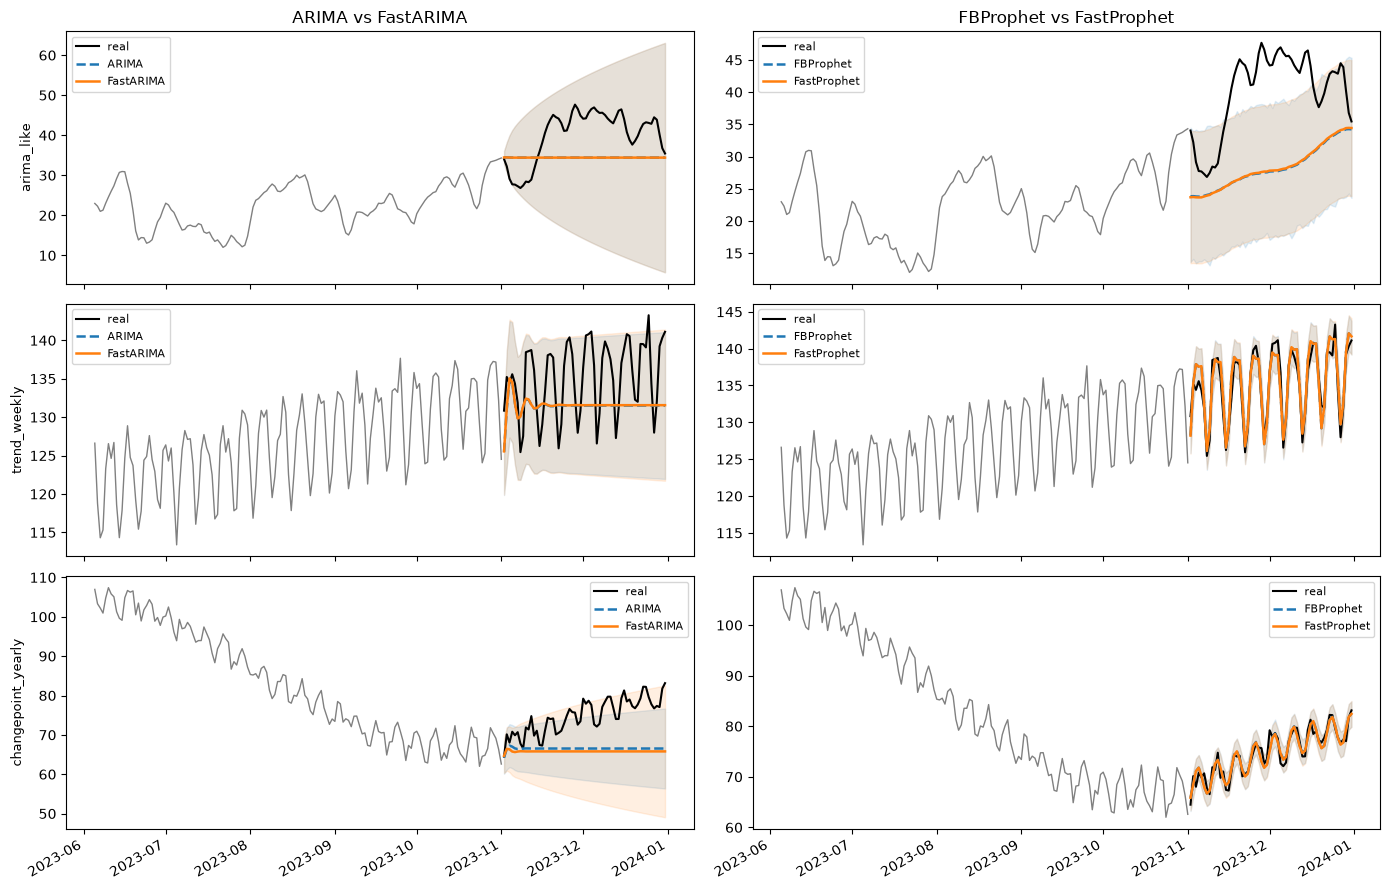

In [20]:
PAIRS = [("ARIMA", "FastARIMA"), ("FBProphet", "FastProphet")]
STYLE = {"ARIMA": ("#1f77b4", "--"), "FBProphet": ("#1f77b4", "--"),
         "FastARIMA": ("#ff7f0e", "-"), "FastProphet": ("#ff7f0e", "-")}
tail = train.iloc[-150:]

fig, axes = plt.subplots(len(df.columns), 2, figsize=(14, 9), sharex="col")
for r, series_name in enumerate(df.columns):
    for c, pair in enumerate(PAIRS):
        ax = axes[r, c]
        ax.plot(tail.index, tail[series_name], color="0.5", lw=1)
        ax.plot(test.index, test[series_name], color="black", lw=1.5, label="real")
        for model_name in pair:
            if model_name not in fitted:
                continue
            _, pred, _ = fitted[model_name]
            color, ls = STYLE[model_name]
            ax.plot(pred.forecast.index, pred.forecast[series_name], color=color, ls=ls, lw=1.8, label=model_name)
            ax.fill_between(pred.forecast.index, pred.lower_forecast[series_name],
                            pred.upper_forecast[series_name], color=color, alpha=0.12)
        if r == 0:
            ax.set_title(" vs ".join(pair))
        if c == 0:
            ax.set_ylabel(series_name, fontsize=9)
        ax.legend(fontsize=8, loc="best")
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

## 5. Notas para interpretar

- Las diferencias de MAE entre original y rápido suelen ser pequeñas: ambos resuelven el mismo modelo; `FastARIMA` usa suma de cuadrados condicional (no MLE exacto) y `FastProphet` usa el modo posterior en forma cerrada (no Stan).
- Con pocas series el speedup ya es grande; la ventaja crece con el número de series porque los rápidos ajustan todas a la vez.
- El intervalo de `FastProphet` es analítico (ruido + incertidumbre de cambios de tendencia futuros), mientras que Prophet simula; deberían ser parecidos, no idénticos.
- La memoria de `FastARIMA` crece con el número de series (ver `TODO.md`).